# Radar line-of-sight velocity maps

Edit the settings below, then run all cells using the `dff` conda kernel. Requires numpy, pandas, matplotlib, cartopy, pyproj, pydarn and pydarnio (install Jupyter/ipykernel to run interactively). Reads local `data/YYYYMMDD/RADAR/*.fitacf[3].bz2`; no DFF or MAP2 file is needed.

Each map contains all observations in a half-open time window `[start, end)`, without temporal averaging. The final window is clipped to the requested end. Times are UT; an end earlier than the start means the following day. Equal start/end times are rejected. Ground scatter (`gflg=1`) uses circles; ionospheric scatter (`gflg=0`) uses dots. Unknown flags are excluded. Positive velocity points **toward** the radar; negative velocity points away. These are measured LOS components, not reconstructed horizontal flow vectors.

Positions use pyDARN's geographic gate centers and standard virtual-height propagation model, with date-specific hardware and each record's range settings. Ground scatter uses the same positioning model: positions are approximate and are not a dedicated ground-scatter range inversion. Zero-speed returns have markers but no visible arrows. Both scatter types share a fixed velocity color scale across all maps.

Maps are arranged in one grid with a shared velocity colorbar and saved as a single PNG. Set `GRID_COLUMNS` to change the layout.

Coordinate selection: `COORDINATES="aacgmv2"` (default) shows AACGM-v2 latitude/longitude with transformed coastlines, `"aacgmv2_mlt"` shows magnetic latitude versus MLT, and `"geographic"` restores the geographic map. The local `sd_carto.py` utility was copied from `meso_tracers/plotting_utils/sd_carto.py`. Each panel uses its window midpoint for all coordinate conversions, including coastlines and radar sites. Geographic arrow bases and endpoints are both converted before projection. Magnetic grid labels are magnetic degrees (or MLT hours). Set the extent for the chosen coordinate system independently. All conversions use `AACGM_HEIGHT_KM`; radar markers are reference positions at that conversion altitude. Saved files are separated by coordinate mode.

Ground scatter defaults to a constant grey for both markers and arrows. Set `GROUND_SCATTER_CONSTANT_COLOR=False` to restore velocity colors. Adjust `GROUND_DOT_SIZE` and `IONOSPHERIC_DOT_SIZE` independently (marker areas in points squared). The velocity colorbar applies only to velocity-colored observations.


In [66]:
import bz2
import datetime as dt
from functools import lru_cache
from pathlib import Path
import os
import warnings

import cmcrameri as cmc

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "event_list.py").exists():
    raise RuntimeError("Start the notebook with the steve_stats project as the working directory.")
os.environ.setdefault("MPLCONFIGDIR", str(PROJECT_ROOT / ".cache/matplotlib"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.lines import Line2D
import cartopy.crs as ccrs
from pyproj import Geod
import pydarn
import pydarnio
import aacgmv2
from sd_carto import SDCarto  # copied from meso_tracers/plotting_utils/sd_carto.py
from pydarn.utils.coordinates import gate2geographic_location
from IPython.display import display



In [ ]:
EVENT_DATE = "2011-04-02"
START_TIME = "04:30"
END_TIME = "06:30"
TIME_DELTA = "10min"  # pandas duration string or datetime.timedelta
RADARS = ["cve", "cvw", "bks", "fhw", "fhe"]
SCATTER = "both"  # "ground", "ionospheric", or "both"

cmap = cmc.cm.berlin_r#plt.get_cmap("RdBu_r")

DATA_ROOT = "data"
SAVE_MAPS = True
OUTPUT_ROOT = "outputs/los_maps"
MAP_EXTENT = [-130, -45, 30, 85]  # west, east, south, north (geographic degrees)
VELOCITY_LIMIT = 400  # m/s; colors saturate beyond +/- this value
VECTOR_SECONDS = 120  # display scale: 1000 m/s arrow spans 120 km
COASTLINES = True  # first use may download Cartopy Natural Earth coastlines

GRID_COLUMNS = 3  # number of maps per row

COORDINATES = "aacgmv2"  # "aacgmv2", "aacgmv2_mlt", or "geographic"
AACGM_HEIGHT_KM = 300  # same conversion altitude for data, radar markers and coastlines
AACGM_EXTENT = [-100, 50, 45, 85]  # magnetic longitude, magnetic latitude
MLT_EXTENT = [-180, 180, 40, 90]  # longitude = MLT hours * 15, wrapped to +/-180

GROUND_SCATTER_CONSTANT_COLOR = True  # False colors ground scatter by velocity
GROUND_SCATTER_COLOR = "grey"  # Matplotlib color, applied to ground dots and arrows
GROUND_DOT_SIZE = 12  # marker area in points squared
IONOSPHERIC_DOT_SIZE = 10  # marker area in points squared


DFF_SAVE_MAPS = True  # save DFF grid independently of LOS SAVE_MAPS
DFF_VELOCITY_LIMIT = 800  # speed colorbar: 0 to this value (m/s)

DFF_CMAP = cmc.cm.batlow
DFF_ARROW_WIDTH = 0.003#0.006  # same width as tracers_sd/notebooks/dff_polar_panel.ipynb
DFF_ARROW_HEADWIDTH = 4
DFF_ARROW_HEADLENGTH = 5
DFF_ARROW_HEADAXISLENGTH = 3
DFF_VECTOR_SECONDS = 600  # display scale: 1000 m/s spans 600 km; increase for longer arrows

if any(not np.isfinite(size) or size < 0 for size in (GROUND_DOT_SIZE, IONOSPHERIC_DOT_SIZE)):
    raise ValueError("Dot sizes must be finite, nonnegative areas in points squared.")

start = pd.Timestamp(f"{EVENT_DATE} {START_TIME}")
end = pd.Timestamp(f"{EVENT_DATE} {END_TIME}")
if start == end:
    raise ValueError("Start and end must differ.")
if end < start:
    end += pd.Timedelta(days=1)
step = pd.Timedelta(TIME_DELTA)
if pd.isna(step) or step <= pd.Timedelta(0):
    raise ValueError("TIME_DELTA must be positive.")
if SCATTER not in {"both", "ground", "ionospheric"}:
    raise ValueError("SCATTER must be both, ground, or ionospheric.")
radars = list(dict.fromkeys(str(r).strip().lower() for r in RADARS))
if not radars or VELOCITY_LIMIT <= 0 or VECTOR_SECONDS <= 0:
    raise ValueError("Select radars and positive velocity/display scales.")
data_root = (PROJECT_ROOT / DATA_ROOT).resolve()
if COORDINATES not in {"geographic", "aacgmv2", "aacgmv2_mlt"}:
    raise ValueError("COORDINATES must be geographic, aacgmv2, or aacgmv2_mlt.")
output_dir = PROJECT_ROOT / OUTPUT_ROOT / start.strftime("%Y%m%d") / SCATTER / COORDINATES
windows = [(t, min(t + step, end)) for t in pd.date_range(start, end, freq=step, inclusive="left")]
print(f"{len(windows)} windows: {start} to {end} UT; scatter={SCATTER}")


12 windows: 2011-04-02 04:30:00 to 2011-04-02 05:30:00 UT; scatter=both


In [68]:
def record_time(record):
    return dt.datetime(*(int(record[f"time.{key}"]) for key in
                         ("yr", "mo", "dy", "hr", "mt", "sc")),
                       microsecond=int(record.get("time.us", 0)))


def read_records(path):
    with bz2.open(path, "rb") as stream:
        raw = stream.read()
    if hasattr(pydarn, "SuperDARNRead"):
        return pydarn.SuperDARNRead(raw, True).read_fitacf()
    records = pydarnio.read_fitacf(raw)
    return records[0] if isinstance(records, tuple) else records


@lru_cache(maxsize=None)
def gate_position(station, radar, day, beam, gate, frang, rsep):
    # pyDARN's geometry reads hardware from its registry. Restore after use.
    radar_info = pydarn.SuperDARNRadars.radars[pydarn.RadarID(station)]
    original = radar_info.hardware_info
    hardware = pydarn.read_hdw_file(radar, date=dt.datetime.fromisoformat(day))
    try:
        pydarn.SuperDARNRadars.radars[pydarn.RadarID(station)] = radar_info._replace(hardware_info=hardware)
        lat, lon = gate2geographic_location(
            stid=pydarn.RadarID(station), beam=beam, range_gate=gate,
            frang=frang, rsep=rsep, center=True, height=300)
    finally:
        pydarn.SuperDARNRadars.radars[pydarn.RadarID(station)] = radar_info
    return float(lat), float(lon), hardware.geographic.lat, hardware.geographic.lon


rows, inventory = [], []
for day in pd.date_range(start.normalize(), (end - pd.Timedelta(nanoseconds=1)).normalize(), freq="D"):
    for radar in radars:
        folder = data_root / day.strftime("%Y%m%d") / radar
        files = sorted(folder.glob("*.fitacf3.bz2")) or sorted(folder.glob("*.fitacf.bz2"))
        inventory.append({"date": str(day.date()), "radar": radar, "files": len(files)})
        if not files:
            warnings.warn(f"No files for {radar} on {day.date()} in {folder}")
        for path in files:
            # Read every daily file: avoids assuming archive file duration.
            for record in read_records(path):
                time = record_time(record)
                if not start <= time < end or "slist" not in record:
                    continue
                gates = record["slist"]
                velocities, flags = record.get("v", []), record.get("gflg", [])
                if not (len(gates) == len(velocities) == len(flags)):
                    warnings.warn(f"Skipping inconsistent arrays in {path.name} at {time}")
                    continue
                for gate, velocity, flag in zip(gates, velocities, flags):
                    if flag not in (0, 1) or not np.isfinite(velocity):
                        continue
                    lat, lon, radar_lat, radar_lon = gate_position(
                        int(record["stid"]), radar, time.date().isoformat(),
                        int(record["bmnum"]), int(gate), float(record["frang"]), float(record["rsep"]))
                    if np.isfinite(lat) and np.isfinite(lon):
                        rows.append((time, radar, lat, lon, radar_lat, radar_lon, float(velocity), int(flag)))
observations = pd.DataFrame(rows, columns=["time", "radar", "lat", "lon", "radar_lat", "radar_lon", "velocity", "gflg"])
display(pd.DataFrame(inventory))
if observations.empty:
    raise RuntimeError("No finite LOS observations in this interval. Check the inventory, date and times.")
if SCATTER != "both":
    observations = observations.loc[observations.gflg.eq(1 if SCATTER == "ground" else 0)].copy()
print(f"Selected {len(observations):,} observations.")


/tmp/ipykernel_283390/1922861076.py: 39: UserWarning: No files for fhw on 2011-04-02 in /home/bharat/Documents/new_code/steve_stats/data/20110402/fhw
/tmp/ipykernel_283390/1922861076.py: 39: UserWarning: No files for fhe on 2011-04-02 in /home/bharat/Documents/new_code/steve_stats/data/20110402/fhe


,date,radar,files
0,2011-04-02,cve,12
1,2011-04-02,cvw,12
2,2011-04-02,bks,12
3,2011-04-02,fhw,0
4,2011-04-02,fhe,0


Selected 44,347 observations.


Saved grid: /home/bharat/Documents/new_code/steve_stats/outputs/los_maps/20110402/both/aacgmv2/los_grid_20110402T043000_20110402T053000.png


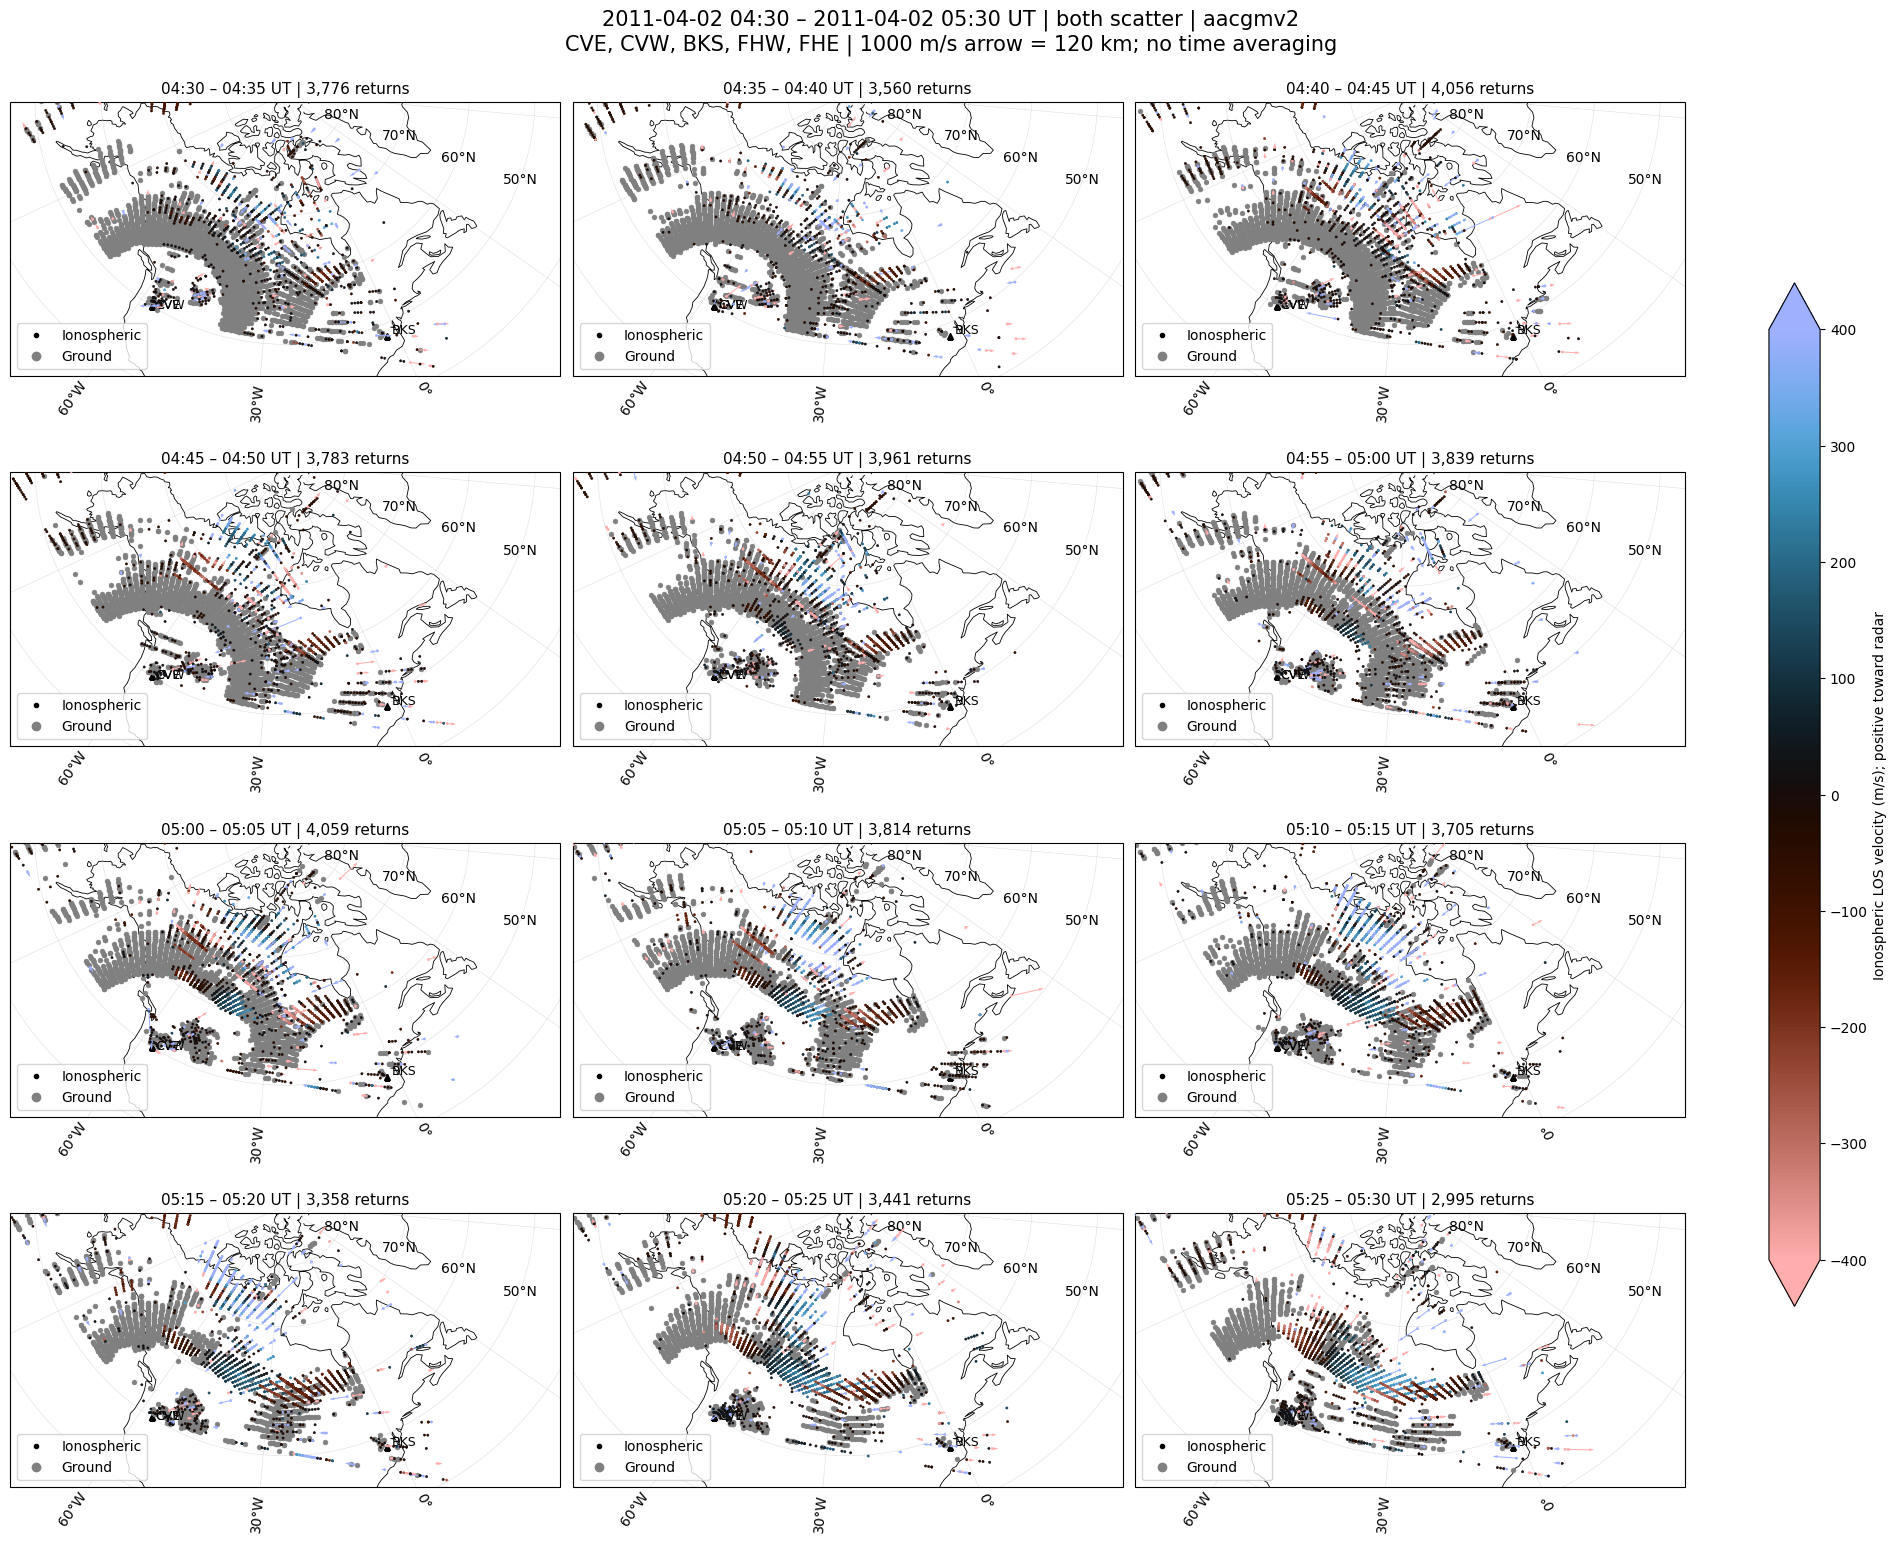

,start_UT,end_UT,returns,radars_with_returns
0,2011-04-02 04:30:00,2011-04-02 04:35:00,3776,"bks, cve, cvw"
1,2011-04-02 04:35:00,2011-04-02 04:40:00,3560,"bks, cve, cvw"
2,2011-04-02 04:40:00,2011-04-02 04:45:00,4056,"bks, cve, cvw"
3,2011-04-02 04:45:00,2011-04-02 04:50:00,3783,"bks, cve, cvw"
4,2011-04-02 04:50:00,2011-04-02 04:55:00,3961,"bks, cve, cvw"
5,2011-04-02 04:55:00,2011-04-02 05:00:00,3839,"bks, cve, cvw"
6,2011-04-02 05:00:00,2011-04-02 05:05:00,4059,"bks, cve, cvw"
7,2011-04-02 05:05:00,2011-04-02 05:10:00,3814,"bks, cve, cvw"
8,2011-04-02 05:10:00,2011-04-02 05:15:00,3705,"bks, cve, cvw"
9,2011-04-02 05:15:00,2011-04-02 05:20:00,3358,"bks, cve, cvw"


In [69]:
geod = Geod(ellps="WGS84")
if COORDINATES == "geographic":
    projection = ccrs.LambertConformal(central_longitude=-95, central_latitude=55)
    extent = MAP_EXTENT
elif COORDINATES == "aacgmv2":
    projection = ccrs.NorthPolarStereo(central_longitude=-25)
    extent = AACGM_EXTENT
else:
    projection = ccrs.NorthPolarStereo(central_longitude=0)
    extent = MLT_EXTENT


def map_coordinates(lon, lat, timestamp):
    """Convert geographic points; the same timestamp is used throughout a panel."""
    lon, lat = np.atleast_1d(lon).astype(float), np.atleast_1d(lat).astype(float)
    if COORDINATES == "geographic":
        return lon, lat
    mlat, mlon, _ = aacgmv2.convert_latlon_arr(
        lat, lon, AACGM_HEIGHT_KM, timestamp.to_pydatetime(), method_code="G2A")
    if COORDINATES == "aacgmv2_mlt":
        mlon = np.asarray(aacgmv2.convert_mlt(mlon, timestamp.to_pydatetime())) * 15
    return (np.asarray(mlon) + 180) % 360 - 180, np.asarray(mlat)

geo = ccrs.PlateCarree()
norm = Normalize(-VELOCITY_LIMIT, VELOCITY_LIMIT)

if SAVE_MAPS:
    output_dir.mkdir(parents=True, exist_ok=True)
summary = []
columns = min(GRID_COLUMNS, len(windows))
if columns < 1:
    raise ValueError("GRID_COLUMNS must be a positive integer.")
row_count = (len(windows) + columns - 1) // columns
# Match subplot slots to the projected map bounds, which can be much wider
# than tall in AACGM mode. Square slots otherwise leave large gaps between rows.
probe_fig = plt.figure()
probe_ax = probe_fig.add_subplot(projection=projection)
probe_ax.set_extent(extent, crs=geo)
xmin, xmax = probe_ax.get_xlim()
ymin, ymax = probe_ax.get_ylim()
panel_aspect = (ymax - ymin) / (xmax - xmin)
plt.close(probe_fig)
panel_width = 6
panel_height = panel_width * panel_aspect + 0.65  # room for titles and tick labels
fig = plt.figure(figsize=(panel_width * columns + 0.9,
                          panel_height * row_count + 0.8), layout="constrained")
fig.get_layout_engine().set(h_pad=0.04, w_pad=0.04, hspace=0.02, wspace=0.02)
axes = []
for index, (left, right) in enumerate(windows):
    panel_time = left + (right - left) / 2
    ax = fig.add_subplot(row_count, columns, index + 1, projection="sdcarto",
                         map_projection=projection, plot_date=panel_time.to_pydatetime(),
                         coords="geo" if COORDINATES == "geographic" else COORDINATES)
    ax.aacgm_height = AACGM_HEIGHT_KM
    axes.append(ax)
    frame = observations.loc[(observations.time >= left) & (observations.time < right)]
    ax.set_extent(extent, crs=geo)
    if COASTLINES:
        ax.coastlines(resolution="110m", linewidth=0.6)
    grid = ax.gridlines(draw_labels={"bottom": "x", "left": "y"}, linewidth=0.4, alpha=0.4)
    if COORDINATES == "aacgmv2_mlt":
        from matplotlib.ticker import FuncFormatter
        grid.xformatter = FuncFormatter(lambda value, pos: f"{(value / 15) % 24:g}h")
    for flag, marker, size in [(0, ".", IONOSPHERIC_DOT_SIZE), (1, "o", GROUND_DOT_SIZE)]:
        subset = frame.loc[frame.gflg.eq(flag)]
        if subset.empty:
            continue
        lon, lat, velocity = (subset[c].to_numpy() for c in ("lon", "lat", "velocity"))
        toward, _, _ = geod.inv(lon, lat, subset.radar_lon.to_numpy(), subset.radar_lat.to_numpy())
        bearing = toward + np.where(velocity >= 0, 0, 180)
        tip_lon, tip_lat, _ = geod.fwd(lon, lat, bearing, np.abs(velocity) * VECTOR_SECONDS)
        lon, lat = map_coordinates(lon, lat, panel_time)
        tip_lon, tip_lat = map_coordinates(tip_lon, tip_lat, panel_time)
        base_xy = projection.transform_points(geo, lon, lat)
        tip_xy = projection.transform_points(geo, tip_lon, tip_lat)
        scatter_zorder = 4 if flag == 0 else 2  # ionospheric above ground
        constant_ground = flag == 1 and GROUND_SCATTER_CONSTANT_COLOR
        if constant_ground:
            quiver_values = ()
            quiver_colors = {"color": GROUND_SCATTER_COLOR}
            dot_colors = {"color": GROUND_SCATTER_COLOR}
        else:
            quiver_values = (velocity,)
            quiver_colors = {"cmap": cmap, "norm": norm}
            dot_colors = {"c": velocity, "cmap": cmap, "norm": norm}
        ax.quiver(base_xy[:, 0], base_xy[:, 1], tip_xy[:, 0] - base_xy[:, 0],
                  tip_xy[:, 1] - base_xy[:, 1], *quiver_values, **quiver_colors,
                  angles="xy", scale_units="xy", scale=1, width=0.0018,
                  zorder=scatter_zorder)
        ax.scatter(lon, lat, **dot_colors, marker=marker,
                   s=size, transform=geo, linewidths=0.4, zorder=scatter_zorder + 0.1)
    # Include available selected radar sites even in windows without returns.
    sites = pd.DataFrame(rows, columns=["time", "radar", "lat", "lon", "radar_lat", "radar_lon", "velocity", "gflg"])
    for radar, site in sites.groupby("radar", sort=False):
        row = site.iloc[0]
        site_lon, site_lat = map_coordinates(row.radar_lon, row.radar_lat, panel_time)
        ax.plot(site_lon, site_lat, "k^", ms=5, transform=geo)
        ax.text(site_lon[0] + 1, site_lat[0], radar.upper(), transform=geo, fontsize=9)
    if frame.empty:
        ax.text(0.5, 0.5, "No selected scatter in this window", transform=ax.transAxes, ha="center")
    handles = [Line2D([], [], color=GROUND_SCATTER_COLOR if flag == 1 and GROUND_SCATTER_CONSTANT_COLOR else "k",
                      marker=m, linestyle="None", label=label)
               for flag, m, label in [(0, ".", "Ionospheric"), (1, "o", "Ground")]
               if SCATTER == "both" or (flag == 1) == (SCATTER == "ground")]
    ax.legend(handles=handles, loc="lower left")
    ax.set_title(f"{left:%H:%M} – {right:%H:%M} UT | {len(frame):,} returns", fontsize=11)
    summary.append({"start_UT": left, "end_UT": right, "returns": len(frame),
                    "radars_with_returns": ", ".join(sorted(frame.radar.unique()))})
fig.suptitle(f"{start:%Y-%m-%d %H:%M} – {end:%Y-%m-%d %H:%M} UT | {SCATTER} scatter | {COORDINATES}\n"
             f"{', '.join(r.upper() for r in radars)} | 1000 m/s arrow = {VECTOR_SECONDS:g} km; no time averaging",
             fontsize=15)
if SCATTER != "ground" or not GROUND_SCATTER_CONSTANT_COLOR:
    colorbar_label = "LOS velocity (m/s); positive toward radar"
    if GROUND_SCATTER_CONSTANT_COLOR and SCATTER == "both":
        colorbar_label = "Ionospheric " + colorbar_label
    fig.colorbar(ScalarMappable(norm=norm, cmap=cmap), ax=axes,
                 shrink=0.7, label=colorbar_label, extend="both")
if SAVE_MAPS:
    grid_path = output_dir / f"los_grid_{start:%Y%m%dT%H%M%S}_{end:%Y%m%dT%H%M%S}.png"
    fig.savefig(grid_path, dpi=150, bbox_inches="tight")
    print(f"Saved grid: {grid_path}")
display(fig)
plt.close(fig)
display(pd.DataFrame(summary))


## DFF vectors for the selected interval and radars
Fits a snapshot at each window midpoint using the available selected radars and packaged DFF defaults (ionospheric input filtering, independent of `SCATTER`). Requires local MAP2 files. Daily saved DFF files use all radars, so this cell refits to honor the selection. Colors represent fitted speed; arrows use magnetic east/north components. The grid is saved separately under `outputs/los_maps/YYYYMMDD/dff/`.

DFF styling follows `tracers_sd/notebooks/dff_polar_panel.ipynb`: batlow speed colors, arrow width 0.006, head dimensions 4/5/3, and z-order 30. No dot overlay is drawn. Adjust `DFF_ARROW_WIDTH`, the head settings, and `DFF_VECTOR_SECONDS` in the following cell.

Fitting settings are loaded from the local `config/dff_config.json`. Edit that file and rerun the DFF cell to apply changes. The notebook controls its own map styling and passes input/output paths explicitly.


20110402: all 3 radar input caches already exist.
Fitting DFF 2011-04-02 04:32:30 UT: cve, cvw, bks


/tmp/ipykernel_283390/4134591814.py: 23: UserWarning: DFF 2011-04-02: unavailable radars: fhe, fhw


reading data from the following radars--> ['cve', 'cvw', 'bks']
Data directory found. Reading from existing parquet files!
parquet file found for--> cve
parquet file found for--> cvw
parquet file found for--> bks
**********************************
concatenating data!
Fitting DFF 2011-04-02 04:37:30 UT: cve, cvw, bks
reading data from the following radars--> ['cve', 'cvw', 'bks']
Data directory found. Reading from existing parquet files!
parquet file found for--> cve
parquet file found for--> cvw
parquet file found for--> bks
**********************************
concatenating data!
Fitting DFF 2011-04-02 04:42:30 UT: cve, cvw, bks
reading data from the following radars--> ['cve', 'cvw', 'bks']
Data directory found. Reading from existing parquet files!
parquet file found for--> cve
parquet file found for--> cvw
parquet file found for--> bks
**********************************
concatenating data!
Fitting DFF 2011-04-02 04:47:30 UT: cve, cvw, bks
reading data from the following radars--> ['cv

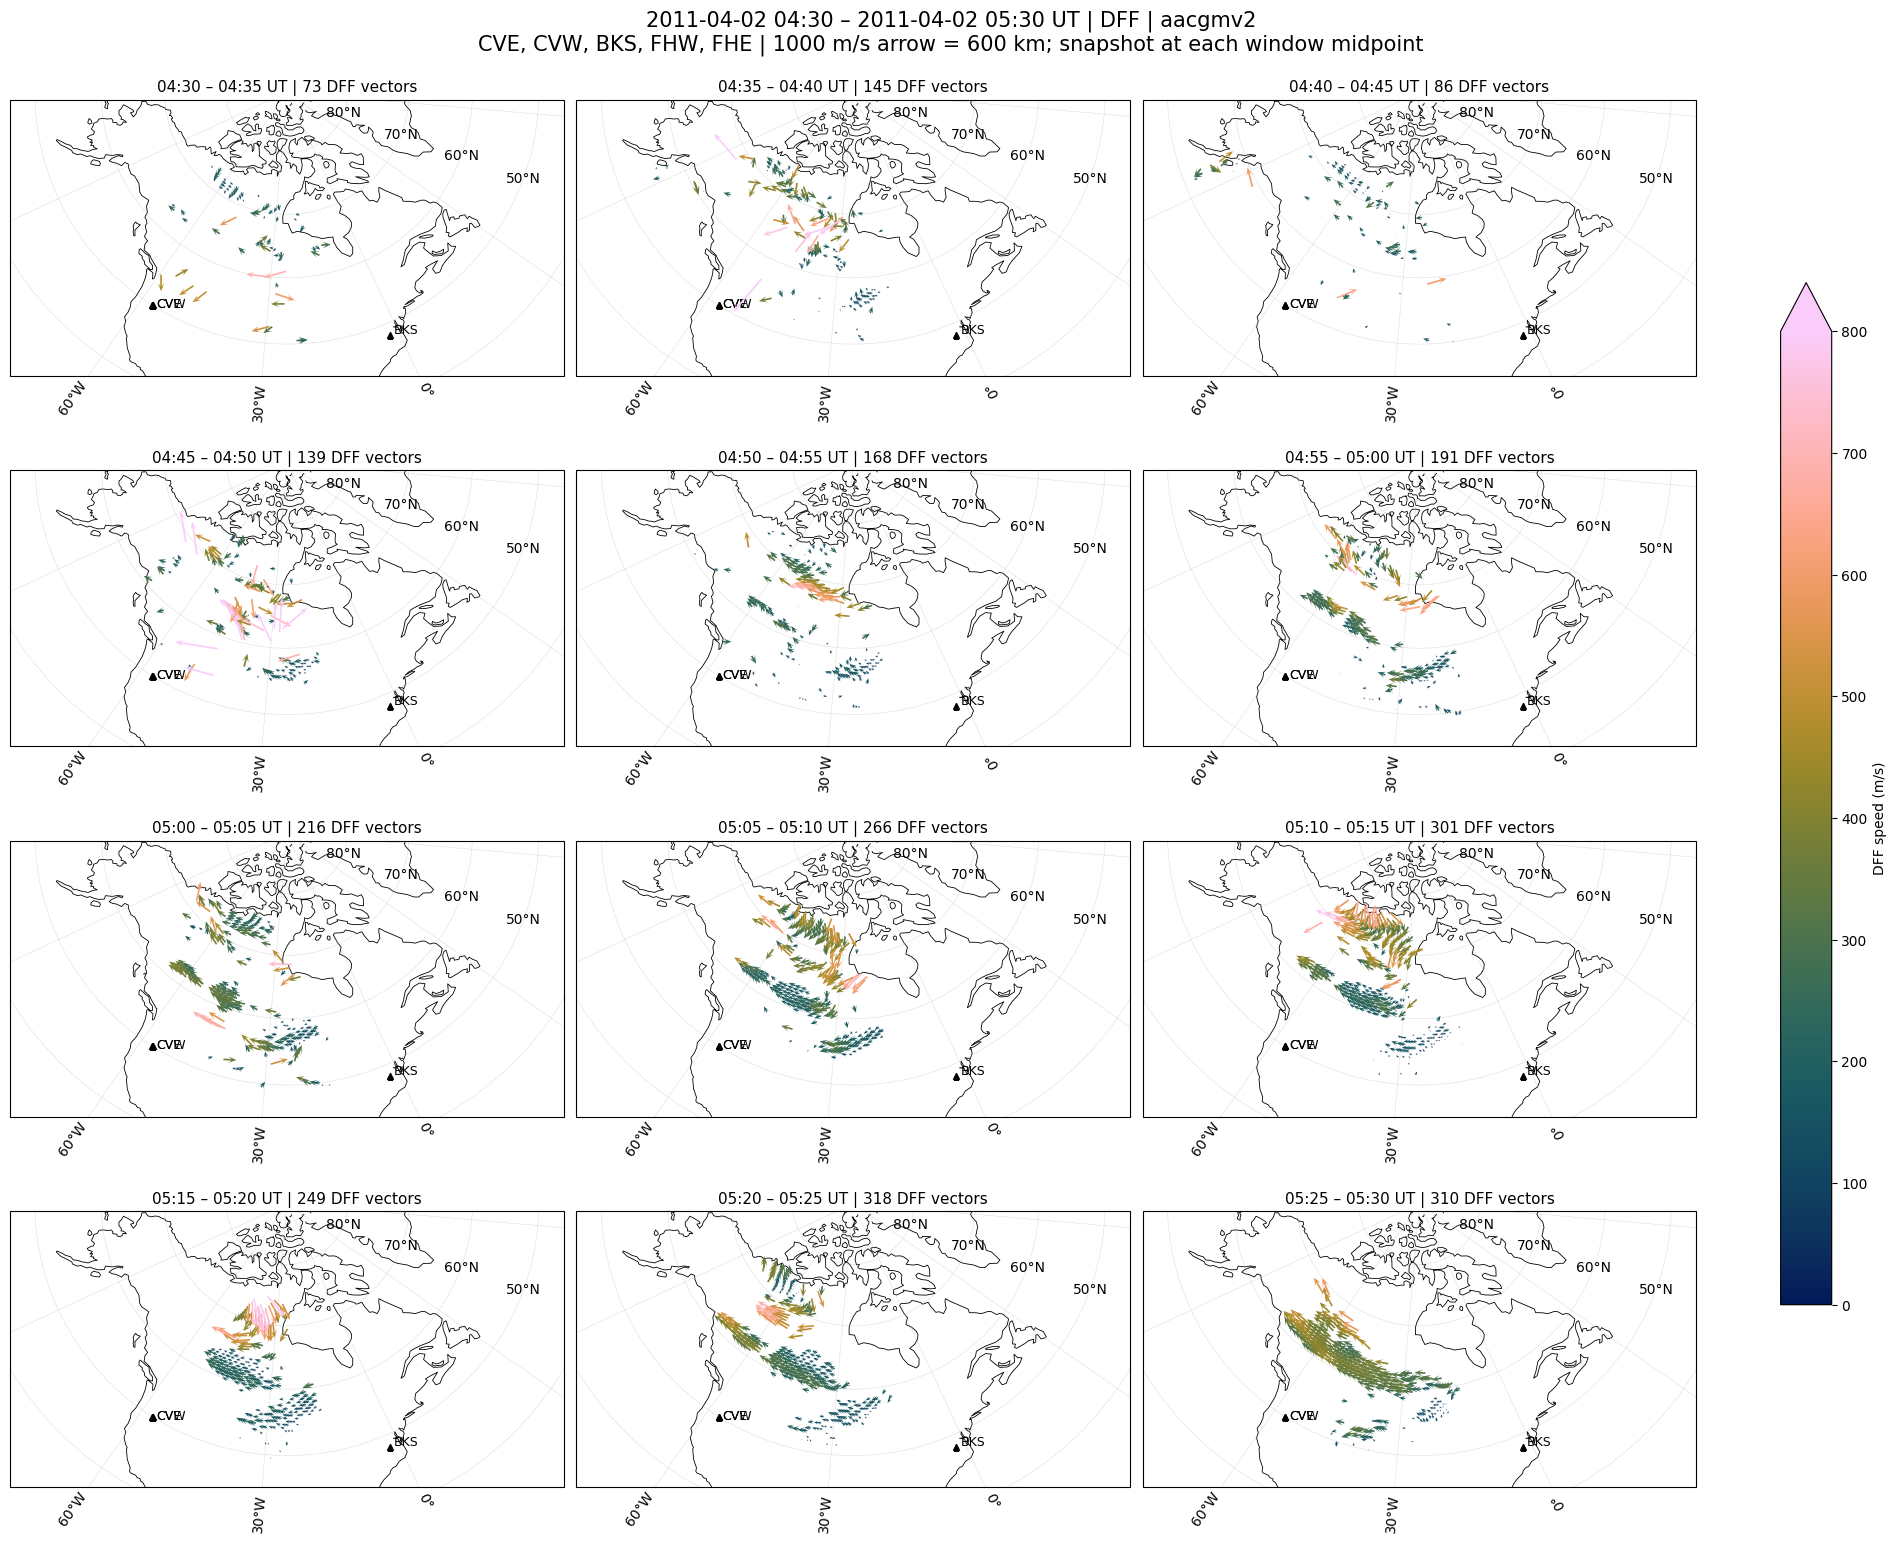

,start_UT,end_UT,returns,radars_with_returns
0,2011-04-02 04:30:00,2011-04-02 04:35:00,73,"cve,cvw,bks"
1,2011-04-02 04:35:00,2011-04-02 04:40:00,145,"cve,cvw,bks"
2,2011-04-02 04:40:00,2011-04-02 04:45:00,86,"cve,cvw,bks"
3,2011-04-02 04:45:00,2011-04-02 04:50:00,139,"cve,cvw,bks"
4,2011-04-02 04:50:00,2011-04-02 04:55:00,168,"cve,cvw,bks"
5,2011-04-02 04:55:00,2011-04-02 05:00:00,191,"cve,cvw,bks"
6,2011-04-02 05:00:00,2011-04-02 05:05:00,216,"cve,cvw,bks"
7,2011-04-02 05:05:00,2011-04-02 05:10:00,266,"cve,cvw,bks"
8,2011-04-02 05:10:00,2011-04-02 05:15:00,301,"cve,cvw,bks"
9,2011-04-02 05:15:00,2011-04-02 05:20:00,249,"cve,cvw,bks"


In [70]:
# Fit once per window at its midpoint using only available selected radars.
# This can take a few minutes. Run the setup/data cells first.
from generate_event_dff import (
    archive_view, use_local_map2, build_fitacf_cache, validate_event_inputs,
    DFFConfig, MakeDFF,
)


if DFF_VELOCITY_LIMIT <= 0:
    raise ValueError("DFF_VELOCITY_LIMIT must be positive.")
dff_frames = []
DFF_CONFIG_PATH = PROJECT_ROOT / "config/dff_config.json"
dff_config = DFFConfig.load(DFF_CONFIG_PATH)
print(f"DFF configuration: {DFF_CONFIG_PATH}")
dff_days = sorted({(left + (right - left) / 2).date() for left, right in windows})
with archive_view(data_root, dff_days) as archive_root:
    with use_local_map2(archive_root):
        for day in dff_days:
            available, _, filetype = validate_event_inputs(data_root, day)
            selected = [radar for radar in radars if radar in available]
            if not selected:
                raise ValueError(f"No selected radar data available on {day}")
            missing = sorted(set(radars) - set(selected))
            if missing:
                warnings.warn(f"DFF {day}: unavailable radars: {', '.join(missing)}")
            build_fitacf_cache(day, selected, filetype, archive_root,
                               data_root / "fitacf_cache", workers=2)
            for left, right in windows:
                midpoint = left + (right - left) / 2
                if midpoint.date() != day:
                    continue
                print(f"Fitting DFF {midpoint} UT: {', '.join(selected)}", flush=True)
                job = MakeDFF(midpoint.to_pydatetime(), selected, hemisphere="North",
                              data_base_dir=str(data_root / "fitacf_cache"),
                              sd_data_base_dir=str(archive_root),
                              outdata_dir=str(PROJECT_ROOT / "outputs/dff_notebook"),
                              dff_config=dff_config)
                _, fitted, _ = job.make_hi_res_fit()
                if "fit_source" in fitted:
                    fitted = fitted.loc[fitted.fit_source.ne("map_prior")].copy()
                fitted = fitted.copy()
                fitted["panel_time"] = midpoint
                fitted["selected_radars"] = ",".join(selected)
                dff_frames.append(fitted)
dff_vectors = pd.concat(dff_frames, ignore_index=True)

geod = Geod(ellps="WGS84")
if COORDINATES == "geographic":
    projection = ccrs.LambertConformal(central_longitude=-95, central_latitude=55)
    extent = MAP_EXTENT
elif COORDINATES == "aacgmv2":
    projection = ccrs.NorthPolarStereo(central_longitude=-25)
    extent = AACGM_EXTENT
else:
    projection = ccrs.NorthPolarStereo(central_longitude=0)
    extent = MLT_EXTENT


def map_coordinates(lon, lat, timestamp):
    """Convert geographic points; the same timestamp is used throughout a panel."""
    lon, lat = np.atleast_1d(lon).astype(float), np.atleast_1d(lat).astype(float)
    if COORDINATES == "geographic":
        return lon, lat
    mlat, mlon, _ = aacgmv2.convert_latlon_arr(
        lat, lon, AACGM_HEIGHT_KM, timestamp.to_pydatetime(), method_code="G2A")
    if COORDINATES == "aacgmv2_mlt":
        mlon = np.asarray(aacgmv2.convert_mlt(mlon, timestamp.to_pydatetime())) * 15
    return (np.asarray(mlon) + 180) % 360 - 180, np.asarray(mlat)

geo = ccrs.PlateCarree()
norm = Normalize(0, DFF_VELOCITY_LIMIT)
dff_output_dir = PROJECT_ROOT / OUTPUT_ROOT / start.strftime("%Y%m%d") / "dff" / COORDINATES

if DFF_SAVE_MAPS:
    dff_output_dir.mkdir(parents=True, exist_ok=True)
summary = []
columns = min(GRID_COLUMNS, len(windows))
if columns < 1:
    raise ValueError("GRID_COLUMNS must be a positive integer.")
row_count = (len(windows) + columns - 1) // columns
# Match subplot slots to the projected map bounds, which can be much wider
# than tall in AACGM mode. Square slots otherwise leave large gaps between rows.
probe_fig = plt.figure()
probe_ax = probe_fig.add_subplot(projection=projection)
probe_ax.set_extent(extent, crs=geo)
xmin, xmax = probe_ax.get_xlim()
ymin, ymax = probe_ax.get_ylim()
panel_aspect = (ymax - ymin) / (xmax - xmin)
plt.close(probe_fig)
panel_width = 6
panel_height = panel_width * panel_aspect + 0.65  # room for titles and tick labels
fig = plt.figure(figsize=(panel_width * columns + 0.9,
                          panel_height * row_count + 0.8), layout="constrained")
fig.get_layout_engine().set(h_pad=0.04, w_pad=0.04, hspace=0.02, wspace=0.02)
axes = []
for index, (left, right) in enumerate(windows):
    panel_time = left + (right - left) / 2
    ax = fig.add_subplot(row_count, columns, index + 1, projection="sdcarto",
                         map_projection=projection, plot_date=panel_time.to_pydatetime(),
                         coords="geo" if COORDINATES == "geographic" else COORDINATES)
    ax.aacgm_height = AACGM_HEIGHT_KM
    axes.append(ax)
    frame = dff_vectors.loc[dff_vectors.panel_time.eq(panel_time)].copy()
    frame = frame.dropna(subset=["mlat", "mlt", "east_vel", "north_vel"])
    ax.set_extent(extent, crs=geo)
    if COASTLINES:
        ax.coastlines(resolution="110m", linewidth=0.6)
    grid = ax.gridlines(draw_labels={"bottom": "x", "left": "y"}, linewidth=0.4, alpha=0.4)
    if COORDINATES == "aacgmv2_mlt":
        from matplotlib.ticker import FuncFormatter
        grid.xformatter = FuncFormatter(lambda value, pos: f"{(value / 15) % 24:g}h")
    if not frame.empty:
        mlat = frame.mlat.to_numpy()
        mlon = np.asarray(aacgmv2.convert_mlt(frame.mlt.to_numpy(), panel_time.to_pydatetime(), m2a=True))
        east, north = frame.east_vel.to_numpy(), frame.north_vel.to_numpy()
        speed = np.hypot(east, north)
        bearing = np.degrees(np.arctan2(east, north))
        # Step in the magnetic tangent plane, then transform both endpoints.
        magnetic_geod = Geod(a=6371000 + AACGM_HEIGHT_KM * 1000, f=0)
        tip_mlon, tip_mlat, _ = magnetic_geod.fwd(mlon, mlat, bearing, speed * DFF_VECTOR_SECONDS)
        if COORDINATES == "geographic":
            lat, lon, _ = aacgmv2.convert_latlon_arr(mlat, mlon, AACGM_HEIGHT_KM,
                                                    panel_time.to_pydatetime(), method_code="A2G")
            tip_lat, tip_lon, _ = aacgmv2.convert_latlon_arr(tip_mlat, tip_mlon, AACGM_HEIGHT_KM,
                                                            panel_time.to_pydatetime(), method_code="A2G")
        elif COORDINATES == "aacgmv2_mlt":
            lat, tip_lat = mlat, tip_mlat
            lon = np.asarray(aacgmv2.convert_mlt(mlon, panel_time.to_pydatetime())) * 15
            tip_lon = np.asarray(aacgmv2.convert_mlt(tip_mlon, panel_time.to_pydatetime())) * 15
        else:
            lon, lat, tip_lon, tip_lat = mlon, mlat, tip_mlon, tip_mlat
        base_xy = projection.transform_points(geo, np.asarray(lon), np.asarray(lat))
        tip_xy = projection.transform_points(geo, np.asarray(tip_lon), np.asarray(tip_lat))
        ax.quiver(base_xy[:, 0], base_xy[:, 1], tip_xy[:, 0] - base_xy[:, 0],
                  tip_xy[:, 1] - base_xy[:, 1], speed, cmap=DFF_CMAP, norm=norm,
                  angles="xy", scale_units="xy", scale=1,
                  width=DFF_ARROW_WIDTH, headwidth=DFF_ARROW_HEADWIDTH,
                  headlength=DFF_ARROW_HEADLENGTH, headaxislength=DFF_ARROW_HEADAXISLENGTH,
                  minlength=0, pivot="tail", zorder=30)
    # Include available selected radar sites even in windows without returns.
    sites = pd.DataFrame(rows, columns=["time", "radar", "lat", "lon", "radar_lat", "radar_lon", "velocity", "gflg"])
    for radar, site in sites.groupby("radar", sort=False):
        row = site.iloc[0]
        site_lon, site_lat = map_coordinates(row.radar_lon, row.radar_lat, panel_time)
        ax.plot(site_lon, site_lat, "k^", ms=5, transform=geo)
        ax.text(site_lon[0] + 1, site_lat[0], radar.upper(), transform=geo, fontsize=9)
    if frame.empty:
        ax.text(0.5, 0.5, "No DFF vectors at window midpoint", transform=ax.transAxes, ha="center")
    ax.set_title(f"{left:%H:%M} – {right:%H:%M} UT | {len(frame):,} DFF vectors", fontsize=11)
    summary.append({"start_UT": left, "end_UT": right, "returns": len(frame),
                    "radars_with_returns": ", ".join(sorted(frame.selected_radars.unique()))})
fig.suptitle(f"{start:%Y-%m-%d %H:%M} – {end:%Y-%m-%d %H:%M} UT | DFF | {COORDINATES}\n"
             f"{', '.join(r.upper() for r in radars)} | 1000 m/s arrow = {DFF_VECTOR_SECONDS:g} km; snapshot at each window midpoint",
             fontsize=15)
fig.colorbar(ScalarMappable(norm=norm, cmap=DFF_CMAP), ax=axes,
             shrink=0.7, label="DFF speed (m/s)", extend="max")
if DFF_SAVE_MAPS:
    dff_grid_path = dff_output_dir / f"dff_grid_{start:%Y%m%dT%H%M%S}_{end:%Y%m%dT%H%M%S}.png"
    fig.savefig(dff_grid_path, dpi=150, bbox_inches="tight")
    print(f"Saved DFF grid: {dff_grid_path}")
display(fig)
plt.close(fig)
display(pd.DataFrame(summary))
